In [ ]:
import pandas as pd

df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')
print(df.head())

   id  age  bp     sg  al  su     rbc        pc         pcc          ba  ...  \
0   0   48  80  1.020   1   0  normal    normal  notpresent  notpresent  ...   
1   1    7  50  1.020   4   0  normal    normal  notpresent  notpresent  ...   
2   2   62  80  1.010   2   3  normal    normal  notpresent  notpresent  ...   
3   3   48  70  1.005   4   0  normal  abnormal     present  notpresent  ...   
4   4   51  80  1.010   2   0  normal    normal  notpresent  notpresent  ...   

   pcv    wc   rc  htn   dm  cad  appet   pe  ane classification  
0   44  7800  5.2  yes  yes   no   good   no   no            ckd  
1   38  6000  4.8   no   no   no   good   no   no            ckd  
2   31  7500  4.8   no  yes   no   poor   no  yes            ckd  
3   32  6700  3.9  yes   no   no   poor  yes  yes            ckd  
4   35  7300  4.6   no   no   no   good   no   no            ckd  

[5 rows x 26 columns]


HASIL STATISTIKA DESKRIPTIF
          Variabel    n   Mean  Median  Minimum  Maksimum  Standar Deviasi  \
0             Usia  250  54.56    59.0      2.0      90.0            17.11   
1    Tekanan Darah  250  79.64    80.0     50.0     180.0            14.93   
2  Kreatinin Serum  250   4.27     2.2      0.5      76.0             6.81   

   Varians  Skewness  Kurtosis  
0   292.67     -1.19      1.40  
1   222.76      1.53      8.01  
2    46.42      6.40     56.42  


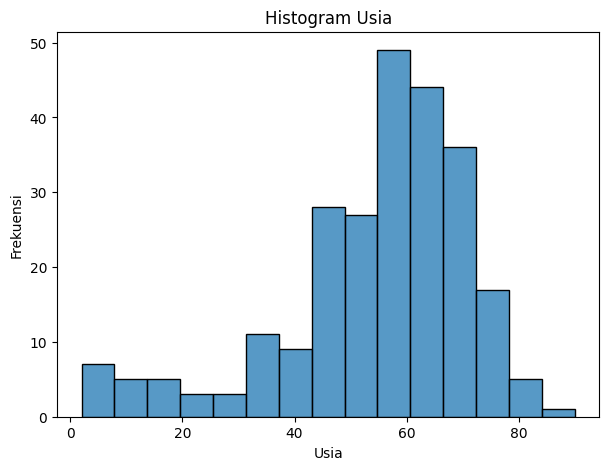

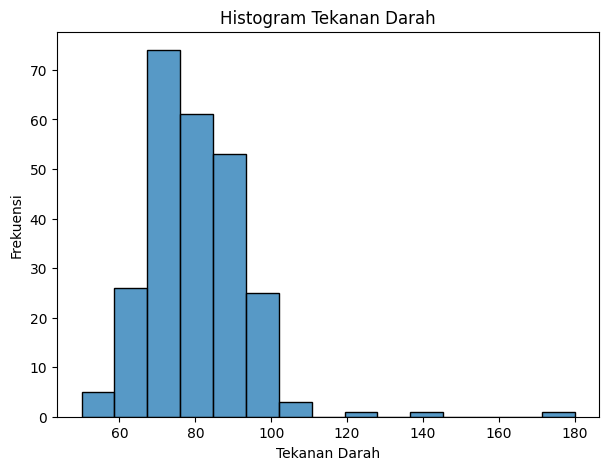

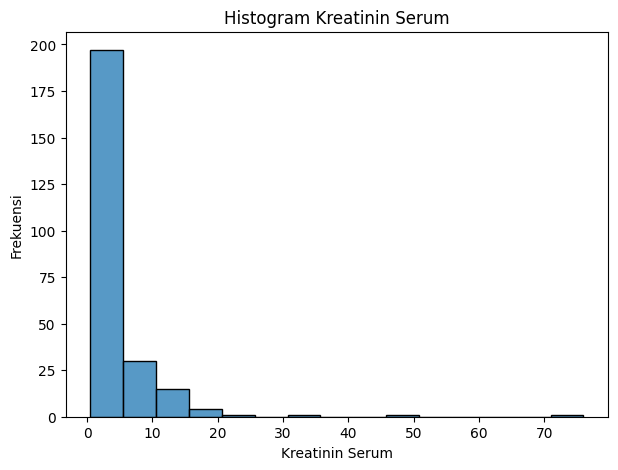

In [ ]:
# ============================================================
# ANALISIS STATISTIKA DESKRIPTIF DATA PASIEN PGK
# Variabel: Usia (age), Tekanan Darah (bp),
#           dan Kreatinin Serum (sc)
# ============================================================

# 1. Mengimpor pustaka yang digunakan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Membaca dataset Chronic Kidney Disease
df = pd.read_excel('3TIB_03_ChronicKidneyDisease.xlsx')


# 3. Memilih data pasien dengan klasifikasi CKD/PGK
# Filter dilakukan berdasarkan kolom classification,
# bukan dengan mengambil 250 baris pertama.
df_ckd = df[df['classification'] == 'ckd'].copy()


# 4. Menentukan variabel yang dianalisis
kolom = ['age', 'bp', 'sc']

# Nama variabel untuk ditampilkan pada tabel dan grafik
labels = {
    'age': 'Usia',
    'bp': 'Tekanan Darah',
    'sc': 'Kreatinin Serum'
}


# 5. Menyiapkan tempat untuk menyimpan hasil perhitungan
hasil = []


# 6. Menghitung statistika deskriptif setiap variabel
for col in kolom:

    # Mengambil data pada setiap variabel dan mengabaikan nilai kosong
    data = df_ckd[col].dropna()

    hasil.append({

        # Jumlah data yang dianalisis
        'Variabel': labels[col],
        'n': len(data),

        # Mean digunakan untuk melihat nilai rata-rata data
        'Mean': data.mean(),

        # Median digunakan untuk melihat nilai tengah data
        'Median': data.median(),

        # Nilai minimum dan maksimum menunjukkan
        # nilai terendah dan tertinggi dalam data
        'Minimum': data.min(),
        'Maksimum': data.max(),

        # Standar deviasi dan varians digunakan
        # untuk menggambarkan penyebaran data
        'Standar Deviasi': data.std(),
        'Varians': data.var(),

        # Skewness digunakan untuk melihat arah kemencengan distribusi
        # Positif = cenderung menceng ke kanan
        # Negatif = cenderung menceng ke kiri
        'Skewness': data.skew(),

        # Kurtosis digunakan untuk membantu menggambarkan
        # karakteristik puncak dan ekor distribusi
        'Kurtosis': data.kurt()
    })


# 7. Mengubah hasil perhitungan menjadi tabel
tabel_hasil = pd.DataFrame(hasil)

# Menampilkan hasil dengan dua angka di belakang koma
print('HASIL STATISTIKA DESKRIPTIF')
print(tabel_hasil.round(2))


# ============================================================
# 8. VISUALISASI DATA MENGGUNAKAN HISTOGRAM
# ============================================================

for col in kolom:

    # Membuat area grafik untuk setiap variabel
    plt.figure(figsize=(7, 5))

    # Histogram digunakan untuk melihat distribusi frekuensi
    # dan pola sebaran masing-masing variabel
    sns.histplot(
        data=df_ckd,
        x=col,
        bins=15
    )

    # Memberikan judul dan label pada grafik
    plt.title(f'Histogram {labels[col]}')
    plt.xlabel(labels[col])
    plt.ylabel('Frekuensi')

    # Menampilkan histogram
    plt.show()